# Phase 6 — Auto-bootstrap Calibration Profile Lifecycle

### HT-9046MX | Candidate profiles, uncertainty, event coverage และ shadow replay

Notebook นี้ตอบคำถามเดียวให้ชัด: **ข้อมูลของแต่ละเครื่อง–โมดูล–SV พร้อมพอที่จะสร้าง candidate profile ระดับใด และอะไรเป็นเหตุให้ยังไปต่อไม่ได้**

คำว่า Auto-bootstrap ในที่นี้หมายถึง lifecycle ของ calibration profile ไม่ใช่ AutoML, bagging หรือการ activate model อัตโนมัติ

## tl;dr

รอบนี้ประเมิน steady profile ทั้งหมด **262 profiles** จากข้อมูลที่ผ่าน state/data gate **2,667,008 minute-windows**

- `SHADOW_VALIDATION`: **39** profiles
- `CANDIDATE_PROFILE`: **3** profiles
- `REVIEW_REQUIRED`: **66** profiles
- `INSUFFICIENT_DATA`: **154** profiles
- Event strata ที่เป็น `INSUFFICIENT_COVERAGE`: **524** จาก 524 strata

ผลลัพธ์นี้เป็น **profile-readiness และ shadow-screening evidence** ไม่ใช่ผลวินิจฉัย leak และไม่มี profile ใดถูกตั้งเป็น `ACTIVE_FROZEN` โดยอัตโนมัติ Source timestamp ยังไม่มี timezone และยังไม่มี service/refill log ที่ยืนยัน epoch จึงต้องให้คนตรวจและอนุมัติก่อนใช้งานจริง

## Context & Methods

### สิ่งที่ Notebook ทำ

1. อ่าน minute-state cache และผล `baseline_stats.csv` ที่สร้างไว้แล้ว
2. ใช้ state rule เดิมเพื่อรักษาความต่อเนื่องกับ Phase 1–5
3. แบ่งเวลาเป็น calibration ช่วงต้นและ shadow ช่วงท้ายต่อ profile
4. ทำ two-pass robust screening: estimate ครั้งแรก → quarantine จุด extreme → estimate candidate ใหม่
5. ตรวจความนิ่งระหว่างครึ่งแรก/ครึ่งหลังและประเมิน uncertainty ด้วย circular moving-block bootstrap ระดับวัน
6. แยก readiness ของ steady profile ออกจาก one-second event profile
7. สร้าง candidate JSON, reason codes และ approval package โดยไม่มีเส้นทาง auto-activate

### Key assumptions

- Grain หลักคือหนึ่งแถวต่อ `machine × module × real clock minute`
- Timestamp ต้นทางไม่มี timezone metadata จึงไม่แปลง timezone
- `Busy/Status` ใช้ working logic เดิมจาก Phase 1 เพื่อเทียบผลย้อนหลัง แต่ยังต้องยืนยันด้วย controller codebook
- ไม่มี recipe/load/facility-water/service log ที่ครบ จึงไม่อนุญาต `READY_FOR_APPROVAL` หรือ `ACTIVE_FROZEN`
- `Hp_2nd = 180–230 psi` เป็น qualified field reference; `<180 psi` เป็น one-sided screening evidence หลัง state qualification ไม่ใช่ label และไม่ใช่ข้อยืนยัน leak

### Chart map

| ภาพ | คำถาม | รูปแบบ |
|---|---|---|
| 1 | profile ส่วนใหญ่หยุดอยู่ขั้นใด | ranked bar |
| 2 | เครื่อง/โมดูลใดพร้อมต่างกันระหว่าง SV Off/On | two-panel categorical heatmap |
| 3 | จำนวนวันช่วยให้ baseline center นิ่งขึ้นหรือไม่ | stability line with median/P90 and cohort size |
| 4 | uncertainty ของ `Hp_2nd` ลดลงตามวันหรือไม่ | full-scale + focused scatter |
| 5 | one-second event ครอบคลุม machine/module/state ใด | heatmap + coverage bar |
| 6 | shadow alert rate สัมพันธ์กับจำนวนตัวอย่างอย่างไร และ profile ใดควรตรวจต่อ | denominator scatter + supported-profile ranking |

## Data

### 1. Setup และแหล่งข้อมูล

In [1]:
import importlib.util
import json
import math
import os
import subprocess
import sys
import warnings
import zlib
from pathlib import Path

required = {
    "polars": "polars>=1.20",
    "pandas": "pandas>=2",
    "numpy": "numpy>=1.26",
    "matplotlib": "matplotlib>=3.8",
    "seaborn": "seaborn>=0.13",
}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_theme(style="whitegrid", context="notebook")

PALETTE = {
    "ink": "#22313F", "blue": "#2F6B9A", "blue_light": "#A9C7DD",
    "gold": "#C7972C", "orange": "#C96A3D", "grey": "#C9CED3",
    "grey_dark": "#66717A", "paper": "#FAFBFC",
}

def find_project_root():
    override = os.environ.get("HT9046MX_PROJECT_ROOT", "").strip()
    candidates = [Path(override)] if override else []
    candidates += [Path.cwd(), Path.cwd().parent, Path("/content/OPERATION_P"), Path("/content/drive/MyDrive/OPERATION_P")]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "README_System.md").exists():
            return candidate
    raise FileNotFoundError("ไม่พบ README_System.md — ตั้ง HT9046MX_PROJECT_ROOT ให้ชี้ไปยังโฟลเดอร์ OPERATION_P")

PROJECT_ROOT = find_project_root()
ANALYSIS_ROOT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_colab_analysis"
EVENT_ROOT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_1s_window_analysis"
OUTPUT_ROOT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_autobootstrap"
FIGURE_ROOT = OUTPUT_ROOT / "figures"
PROFILE_ROOT = OUTPUT_ROOT / "candidate_profiles"
for folder in [OUTPUT_ROOT, FIGURE_ROOT, PROFILE_ROOT]:
    folder.mkdir(parents=True, exist_ok=True)

MINUTE_FILE = ANALYSIS_ROOT / "cache" / "minute_module_state.parquet"
BASELINE_FILE = ANALYSIS_ROOT / "baseline_stats.csv"
EVENT_FILE = EVENT_ROOT / "clean_event_summary.csv"
for path in [PROJECT_ROOT / "README_System.md", PROJECT_ROOT / "SOT.md", MINUTE_FILE, BASELINE_FILE, EVENT_FILE]:
    if not path.exists():
        raise FileNotFoundError(f"Missing required input: {path}")

PROFILE_KEYS = ["machine_number", "module", "sv"]
FEATURES = ["hp1", "lp1", "hp2", "lp2", "valve", "temphi", "templo"]
FEATURE_LABELS = {
    "hp1": "Hp_1st", "lp1": "Lp_1st", "hp2": "Hp_2nd", "lp2": "Lp_2nd",
    "valve": "Valve", "temphi": "TempHigh", "templo": "TempLow",
}
SCALE_FLOORS = {"hp1": 0.10, "lp1": 0.10, "hp2": 0.10, "lp2": 0.10, "valve": 1.0, "temphi": 0.10, "templo": 0.10}

SETTLE_MINUTES = 3
CALIBRATION_FRACTION = 0.70
MIN_STEADY_DAYS = 7
MIN_STEADY_WINDOWS = 200
MIN_SHADOW_DAYS = 3
MIN_EVENT_CANDIDATE = 30
MIN_EVENT_SHADOW = 50
MIN_EVENT_DAYS = 3
QUARANTINE_Z = 8.0
MAX_QUARANTINE_PCT = 5.0
MAX_HALF_SHIFT_RZ = 1.5
BOOTSTRAP_REPLICATES = 400
PROFILE_VERSION = "autobootstrap-candidate-v2-hp180"
FEATURE_VERSION = "minute-state-core-hp180-v2"
SOURCE_TIMEZONE = "not encoded"

def savefig(name):
    path = FIGURE_ROOT / name
    plt.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
    print("Saved:", path)

print("Project:", PROJECT_ROOT)
print("Minute source:", MINUTE_FILE)
print("Event source:", EVENT_FILE)
print("Output:", OUTPUT_ROOT)

Project: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P
Minute source: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_colab_analysis\cache\minute_module_state.parquet
Event source: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_1s_window_analysis\clean_event_summary.csv
Output: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_autobootstrap


### 2. Data Quality Gate

ก่อนสร้าง profile ต้องพิสูจน์ก่อนว่า grain, key, timestamp และ field ที่จำเป็นยังอยู่ครบ

In [2]:
minute = pl.read_parquet(MINUTE_FILE, columns=[
    "machine_number", "minute", "global_status", "module", "module_status", "sv", "busy", *FEATURES
]).sort(["machine_number", "module", "minute"])
baseline_audit = pl.read_csv(BASELINE_FILE, schema_overrides={"machine_number": pl.Utf8})
events = pl.read_csv(EVENT_FILE, try_parse_dates=True, schema_overrides={"machine_number": pl.Utf8})

required_minute = {"machine_number", "module", "minute", "global_status", "module_status", "sv", "busy", *FEATURES}
missing_columns = sorted(required_minute - set(minute.columns))
if missing_columns:
    raise ValueError(f"Minute source missing columns: {missing_columns}")

minute_duplicate_keys = (
    minute.group_by(["machine_number", "module", "minute"]).len().filter(pl.col("len") > 1).height
)
baseline_duplicate_keys = baseline_audit.group_by(PROFILE_KEYS).len().filter(pl.col("len") > 1).height
event_duplicate_ids = events.group_by("event_id").len().filter(pl.col("len") > 1).height
source_start = minute["minute"].min()
source_end = minute["minute"].max()

dq_rows = [
    {"check": "minute required columns", "result": "PASS" if not missing_columns else "FAIL", "evidence": str(missing_columns or "complete")},
    {"check": "minute composite key", "result": "PASS" if minute_duplicate_keys == 0 else "FAIL", "evidence": f"{minute_duplicate_keys:,} duplicated keys"},
    {"check": "baseline profile key", "result": "PASS" if baseline_duplicate_keys == 0 else "FAIL", "evidence": f"{baseline_duplicate_keys:,} duplicated keys"},
    {"check": "event id uniqueness", "result": "PASS" if event_duplicate_ids == 0 else "FAIL", "evidence": f"{event_duplicate_ids:,} duplicated ids"},
    {"check": "timezone metadata", "result": "CAVEAT", "evidence": SOURCE_TIMEZONE},
    {"check": "service/refill epoch", "result": "CAVEAT", "evidence": "service timeline not supplied"},
    {"check": "recipe/load/water context", "result": "CAVEAT", "evidence": "not present in current minute cache"},
]
dq = pd.DataFrame(dq_rows)
dq.to_csv(OUTPUT_ROOT / "data_quality_checks.csv", index=False)
display(dq)
print(f"Minute rows: {minute.height:,} | machines: {minute['machine_number'].n_unique()} | period: {source_start} to {source_end}")

,check,result,evidence
0,minute required columns,PASS,complete
1,minute composite key,PASS,0 duplicated keys
2,baseline profile key,PASS,0 duplicated keys
3,event id uniqueness,PASS,0 duplicated ids
4,timezone metadata,CAVEAT,not encoded
5,service/refill epoch,CAVEAT,service timeline not supplied
6,recipe/load/water context,CAVEAT,not present in current minute cache


Minute rows: 3,548,928 | machines: 19 | period: 2026-08-04 00:00:00 to 2026-09-01 17:10:00


**วิธีอ่าน:** `PASS` หมายถึงตรวจได้จากไฟล์นี้ ส่วน `CAVEAT` หมายถึงข้อมูลที่จำเป็นต่อ Production ยังไม่ถูกส่งมา ไม่ได้หมายความว่าเติมค่าขึ้นมาแทนได้

### 3. ใช้ state rule เดิมและระบุสิ่งที่ถูกตัดออก

In [3]:
control_states = ["ChangeValve", "MValveHome", "AdjustValve"]
minute = minute.with_columns(
    pl.when(pl.col("global_status") == "Stop").then(pl.lit("GLOBAL_STOP"))
    .when((pl.col("module_status").is_in(control_states)) | (pl.col("busy") == 1) | (pl.col("valve") < 0)).then(pl.lit("CONTROL_SEQUENCE"))
    .when(pl.col("module_status") == "Off").then(pl.lit("RUN_MODULE_OFF"))
    .when((pl.col("global_status") == "Run") & (pl.col("module_status") == "On") & (pl.col("busy") == 0) & (pl.col("valve") >= 0) & (pl.col("sv") == "Off")).then(pl.lit("RUN_ON_SV_OFF"))
    .when((pl.col("global_status") == "Run") & (pl.col("module_status") == "On") & (pl.col("busy") == 0) & (pl.col("valve") >= 0) & (pl.col("sv") == "On")).then(pl.lit("RUN_ON_SV_ON"))
    .otherwise(pl.lit("UNCLASSIFIED")).alias("state")
)
minute = minute.with_columns(
    (
        (pl.col("state") != pl.col("state").shift(1).over(["machine_number", "module"]))
        | (pl.col("minute").diff().over(["machine_number", "module"]).dt.total_minutes() > 2)
    ).fill_null(True).alias("segment_start")
).with_columns(
    pl.col("segment_start").cast(pl.Int64).cum_sum().over(["machine_number", "module"]).alias("segment_id")
).with_columns(
    pl.col("minute").cum_count().over(["machine_number", "module", "segment_id"]).alias("minutes_in_state")
)

complete_features = pl.all_horizontal([pl.col(f).is_not_null() & pl.col(f).is_finite() for f in FEATURES])
minute = minute.with_columns(
    (
        pl.col("state").is_in(["RUN_ON_SV_OFF", "RUN_ON_SV_ON"])
        & (pl.col("minutes_in_state") >= SETTLE_MINUTES)
        & complete_features
    ).alias("profile_eligible")
)

state_audit = (
    minute.group_by("state").agg(pl.len().alias("minutes"), pl.col("profile_eligible").sum().alias("eligible_minutes"))
    .sort("minutes", descending=True).to_pandas()
)
state_audit["share_pct"] = 100 * state_audit["minutes"] / state_audit["minutes"].sum()
state_audit.to_csv(OUTPUT_ROOT / "state_gate_audit.csv", index=False)
display(state_audit)

eligible = minute.filter(pl.col("profile_eligible")).select(
    [*PROFILE_KEYS, "minute", "segment_id", *FEATURES]
).with_columns(pl.col("minute").dt.date().alias("date"))
print(f"Eligible minute-windows: {eligible.height:,} ({100*eligible.height/minute.height:.1f}% of minute rows)")

,state,minutes,eligible_minutes,share_pct
0,RUN_ON_SV_OFF,2475455,2468321,69.752190
1,RUN_MODULE_OFF,770732,0,21.717319
2,RUN_ON_SV_ON,201337,198687,5.673178
3,GLOBAL_STOP,88736,0,2.500361
4,CONTROL_SEQUENCE,12668,0,0.356953


Eligible minute-windows: 2,667,008 (75.1% of minute rows)


`CONTROL_SEQUENCE`, stop, negative-valve command และช่วงยังไม่ settle ถูกกันออกจาก profile โดยตรง ส่วน recipe, load, facility water และ service epoch ยังตรวจไม่ได้เพราะไม่มี field ต้นทาง จึงถูกเก็บเป็น approval blocker ไม่ได้ถูกสมมติว่า “ปกติ”

## Results

### 4. Temporal split ต่อ profile — calibration มาก่อน shadow เสมอ

In [4]:
date_lists = (
    eligible.group_by(PROFILE_KEYS).agg(pl.col("date").unique().sort().alias("dates"))
    .sort(PROFILE_KEYS).to_dicts()
)
split_rows = []
for row in date_lists:
    dates = row["dates"]
    if len(dates) >= 3:
        train_count = min(len(dates) - 2, max(1, int(math.ceil(len(dates) * CALIBRATION_FRACTION))))
    elif len(dates) == 2:
        train_count = 1
    else:
        train_count = len(dates)
    calibration_dates = dates[:train_count]
    split_rows.append({
        **{key: row[key] for key in PROFILE_KEYS},
        "total_days": len(dates),
        "calibration_days_planned": train_count,
        "shadow_days_planned": len(dates) - train_count,
        "calibration_cutoff": calibration_dates[-1] if calibration_dates else None,
        "stability_cutoff": calibration_dates[max(0, len(calibration_dates)//2 - 1)] if calibration_dates else None,
    })

splits = pl.from_dicts(split_rows).with_columns(pl.col("machine_number").cast(pl.Utf8))
eligible = eligible.join(splits, on=PROFILE_KEYS, how="left").with_columns(
    (pl.col("date") <= pl.col("calibration_cutoff")).alias("is_calibration")
)
calibration = eligible.filter(pl.col("is_calibration"))
shadow = eligible.filter(~pl.col("is_calibration"))
splits.write_csv(OUTPUT_ROOT / "temporal_profile_splits.csv")
display(splits.select([*PROFILE_KEYS, "total_days", "calibration_days_planned", "shadow_days_planned", "calibration_cutoff"]).head(20).to_pandas())
print(f"Calibration rows: {calibration.height:,} | shadow rows: {shadow.height:,}")

,machine_number,module,sv,total_days,calibration_days_planned,shadow_days_planned,calibration_cutoff
0,017,1,Off,21,15,6,2026-08-26
1,017,1,On,9,7,2,2026-08-29
2,017,2,Off,21,15,6,2026-08-26
3,017,2,On,9,7,2,2026-08-29
4,017,3,Off,21,15,6,2026-08-26
5,017,3,On,9,7,2,2026-08-29
6,017,4,Off,21,15,6,2026-08-26
7,017,4,On,12,9,3,2026-08-28
8,017,5,Off,21,15,6,2026-08-26
9,017,5,On,9,7,2,2026-08-29


Calibration rows: 1,913,308 | shadow rows: 753,700


### 5. Two-pass robust profile และ contamination quarantine

In [5]:
def summarize_profiles(frame: pl.DataFrame) -> pl.DataFrame:
    expressions = [
        pl.len().alias("n_windows"),
        pl.col("date").n_unique().alias("n_days"),
        pl.col("minute").min().alias("source_start"),
        pl.col("minute").max().alias("source_end"),
    ]
    for feature in FEATURES:
        expressions += [
            pl.col(feature).median().alias(f"{feature}__median"),
            pl.col(feature).quantile(0.05).alias(f"{feature}__q05"),
            pl.col(feature).quantile(0.25).alias(f"{feature}__q25"),
            pl.col(feature).quantile(0.75).alias(f"{feature}__q75"),
            pl.col(feature).quantile(0.95).alias(f"{feature}__q95"),
        ]
    summary = frame.group_by(PROFILE_KEYS).agg(*expressions)
    centered = frame.join(summary.select([*PROFILE_KEYS, *[f"{f}__median" for f in FEATURES]]), on=PROFILE_KEYS)
    mad = centered.group_by(PROFILE_KEYS).agg(*[
        (pl.col(f) - pl.col(f"{f}__median")).abs().median().alias(f"{f}__mad") for f in FEATURES
    ])
    summary = summary.join(mad, on=PROFILE_KEYS)
    scale_exprs = []
    for feature in FEATURES:
        iqr_scale = (pl.col(f"{feature}__q75") - pl.col(f"{feature}__q25")) / 1.349
        scale_exprs.append(
            pl.when(pl.col(f"{feature}__mad") / 0.67448975 > SCALE_FLOORS[feature])
            .then(pl.col(f"{feature}__mad") / 0.67448975)
            .when(iqr_scale > SCALE_FLOORS[feature]).then(iqr_scale)
            .otherwise(pl.lit(SCALE_FLOORS[feature])).alias(f"{feature}__scale")
        )
    return summary.with_columns(*scale_exprs).sort(PROFILE_KEYS)

initial_profiles = summarize_profiles(calibration)
profile_columns = [*PROFILE_KEYS]
for feature in FEATURES:
    profile_columns += [f"{feature}__median", f"{feature}__scale"]

calibration_screened = calibration.join(initial_profiles.select(profile_columns), on=PROFILE_KEYS)
z_exprs = [
    ((pl.col(feature) - pl.col(f"{feature}__median")) / pl.col(f"{feature}__scale")).alias(f"z_{feature}")
    for feature in FEATURES
]
calibration_screened = calibration_screened.with_columns(*z_exprs).with_columns(
    pl.max_horizontal([pl.col(f"z_{feature}").abs() for feature in FEATURES]).alias("max_abs_robust_z")
).with_columns((pl.col("max_abs_robust_z") > QUARANTINE_Z).alias("quarantine"))

quarantine_summary = calibration_screened.group_by(PROFILE_KEYS).agg(
    pl.len().alias("screened_windows"),
    pl.col("quarantine").sum().alias("quarantined_windows"),
).with_columns(
    (100 * pl.col("quarantined_windows") / pl.col("screened_windows")).alias("quarantine_pct")
)

retained = calibration_screened.filter(~pl.col("quarantine")).select(
    [*PROFILE_KEYS, "minute", "date", "segment_id", "stability_cutoff", *FEATURES]
)
candidate_profiles = summarize_profiles(retained).join(quarantine_summary, on=PROFILE_KEYS, how="left")
candidate_profiles.write_csv(OUTPUT_ROOT / "candidate_profile_statistics.csv")
quarantine_summary.write_csv(OUTPUT_ROOT / "contamination_screening.csv")

display(candidate_profiles.select([
    *PROFILE_KEYS, "n_windows", "n_days", "quarantine_pct", "hp2__median", "hp2__q05", "hp2__q95", "hp2__scale"
]).head(24).to_pandas())
print(f"Quarantined windows: {int(quarantine_summary['quarantined_windows'].sum()):,} / {int(quarantine_summary['screened_windows'].sum()):,}")

,machine_number,module,sv,n_windows,n_days,quarantine_pct,hp2__median,hp2__q05,hp2__q95,hp2__scale
0,017,1,Off,17086,15,15.595514,195.30,189.8,199.3,3.409985
1,017,1,On,209,7,5.000000,309.70,199.8,325.4,21.645992
2,017,2,Off,18949,15,6.517020,203.60,201.9,205.7,1.037822
3,017,2,On,219,7,0.000000,222.60,207.8,291.8,16.901665
4,017,3,Off,20224,15,0.172763,215.50,210.3,218.3,2.372164
5,017,3,On,219,7,0.000000,229.60,219.5,251.6,9.340394
6,017,4,Off,19890,15,1.889212,198.10,195.6,202.2,1.927383
7,017,4,On,1664,3,11.770944,205.80,203.3,207.7,1.186082
8,017,5,Off,20244,15,0.295508,196.60,194.0,202.3,2.372164
9,017,5,On,168,4,29.411765,195.90,194.9,198.2,0.815431


Quarantined windows: 108,521 / 1,913,308


จุดที่ถูก quarantine ไม่ได้ถูกลบทิ้งจากหลักฐาน ตาราง `contamination_screening.csv` เก็บจำนวนและอัตราไว้ครบ กฎนี้ตัดเฉพาะ extreme multivariate residual มากกว่า 8 robust sigma ในรอบแรก และยังไม่ใช้ model score มารับรองตัวเอง

### 6. ตรวจ stability ระหว่างครึ่งแรกกับครึ่งหลังของ calibration

In [6]:
first_half = retained.filter(pl.col("date") <= pl.col("stability_cutoff"))
second_half = retained.filter(pl.col("date") > pl.col("stability_cutoff"))
first_medians = first_half.group_by(PROFILE_KEYS).agg(*[pl.col(f).median().alias(f"{f}__first") for f in FEATURES])
second_medians = second_half.group_by(PROFILE_KEYS).agg(*[pl.col(f).median().alias(f"{f}__second") for f in FEATURES])

stability = (
    candidate_profiles.select([*PROFILE_KEYS, *[f"{f}__scale" for f in FEATURES]])
    .join(first_medians, on=PROFILE_KEYS, how="left")
    .join(second_medians, on=PROFILE_KEYS, how="left")
)
shift_exprs = [
    ((pl.col(f"{f}__second") - pl.col(f"{f}__first")) / pl.col(f"{f}__scale")).alias(f"{f}__half_shift_rz")
    for f in FEATURES
]
stability = stability.with_columns(*shift_exprs).with_columns(
    pl.max_horizontal([pl.col(f"{f}__half_shift_rz").abs() for f in FEATURES]).alias("max_abs_half_shift_rz")
).sort(PROFILE_KEYS)
stability.write_csv(OUTPUT_ROOT / "profile_half_stability.csv")
display(stability.select([*PROFILE_KEYS, "hp2__half_shift_rz", "lp2__half_shift_rz", "valve__half_shift_rz", "max_abs_half_shift_rz"]).head(24).to_pandas())

,machine_number,module,sv,hp2__half_shift_rz,lp2__half_shift_rz,valve__half_shift_rz,max_abs_half_shift_rz
0,017,1,Off,0.850444,0.758801,0.000000,0.899320
1,017,1,On,2.908160,1.088092,0.000000,2.908160
2,017,2,Off,-0.385423,0.000000,0.000000,0.854354
3,017,2,On,3.842817,1.773658,3.000000,3.842817
4,017,3,Off,-0.379400,-0.674490,0.000000,1.165028
5,017,3,On,0.235536,1.134369,0.000000,1.134369
6,017,4,Off,0.466954,-0.674490,0.000000,0.674490
7,017,4,On,1.601913,-0.224830,0.000000,4.721428
8,017,5,Off,0.421556,0.000000,0.000000,0.674490
9,017,5,On,1.226345,0.809388,0.000000,3.709694


### 7. Day-block bootstrap: วัดความไม่แน่นอนของ baseline center

In [7]:
daily = retained.group_by([*PROFILE_KEYS, "date"]).agg(
    pl.len().alias("n_windows"),
    *[pl.col(f).median().alias(f) for f in FEATURES],
).sort([*PROFILE_KEYS, "date"])
daily_pdf = daily.to_pandas()

def circular_block_indexes(n, block_length, rng):
    starts = rng.integers(0, n, size=math.ceil(n / block_length))
    return np.concatenate([(start + np.arange(block_length)) % n for start in starts])[:n]

bootstrap_rows = []
for key, group in daily_pdf.groupby(PROFILE_KEYS, sort=True):
    group = group.sort_values("date")
    n_days = len(group)
    seed = 9046 + zlib.crc32("|".join(map(str, key)).encode("utf-8"))
    for block_length in sorted(set([1, min(3, n_days)])):
        rng = np.random.default_rng(seed + block_length)
        for feature in FEATURES:
            values = group[feature].dropna().to_numpy(dtype=float)
            if len(values) == 0:
                continue
            estimates = np.array([
                np.median(values[circular_block_indexes(len(values), min(block_length, len(values)), rng)])
                for _ in range(BOOTSTRAP_REPLICATES)
            ])
            bootstrap_rows.append({
                "machine_number": key[0], "module": int(key[1]), "sv": key[2],
                "feature": feature, "n_days": n_days, "block_length_days": block_length,
                "replicates": BOOTSTRAP_REPLICATES, "daily_center": float(np.median(values)),
                "ci_low": float(np.quantile(estimates, 0.025)),
                "ci_high": float(np.quantile(estimates, 0.975)),
                "ci_width": float(np.quantile(estimates, 0.975) - np.quantile(estimates, 0.025)),
            })

bootstrap_ci = pd.DataFrame(bootstrap_rows)
bootstrap_ci.to_csv(OUTPUT_ROOT / "block_bootstrap_uncertainty.csv", index=False)
display(bootstrap_ci[(bootstrap_ci["feature"] == "hp2") & (bootstrap_ci["block_length_days"] > 1)].head(20))

,machine_number,module,sv,feature,n_days,block_length_days,replicates,daily_center,ci_low,ci_high,ci_width
9,017,1,Off,hp2,15,3,400,195.300,191.500,196.700,5.200
23,017,1,On,hp2,7,3,400,313.850,202.400,321.400,119.000
37,017,2,Off,hp2,15,3,400,203.600,203.300,204.700,1.400
51,017,2,On,hp2,7,3,400,282.750,214.500,286.800,72.300
65,017,3,Off,hp2,15,3,400,215.500,213.500,216.700,3.200
79,017,3,On,hp2,7,3,400,227.500,225.300,247.000,21.700
93,017,4,Off,hp2,15,3,400,197.800,197.400,200.700,3.300
107,017,4,On,hp2,3,3,400,205.800,205.800,205.800,0.000
121,017,5,Off,hp2,15,3,400,196.700,195.400,199.400,4.000
135,017,5,On,hp2,4,3,400,196.475,195.650,197.275,1.625


Bootstrap นี้สุ่ม **กลุ่มวันที่ต่อเนื่อง** จาก daily medians เพื่อรักษาการพึ่งพาตามเวลามากกว่าการสุ่มรายนาที ค่า CI จึงสะท้อนความไม่แน่นอนของ baseline center ระหว่างวัน ไม่ใช่ tolerance ของ sensor และไม่ใช่ confidence ว่าเครื่อง healthy

### 8. Profile-stability curve: ต้องเก็บกี่วันจึงเริ่มนิ่ง

,prefix_days,profiles,median_abs_shift_rz,p90_abs_shift_rz
0,3,149,0.481778,1.450153
1,5,126,0.385423,0.924613
2,7,108,0.330500,0.897914
3,10,93,0.245269,0.797893
4,14,64,0.137708,0.587694
5,21,6,0.077940,0.224292


Saved: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_autobootstrap\figures\03_profile_stability_curve.png


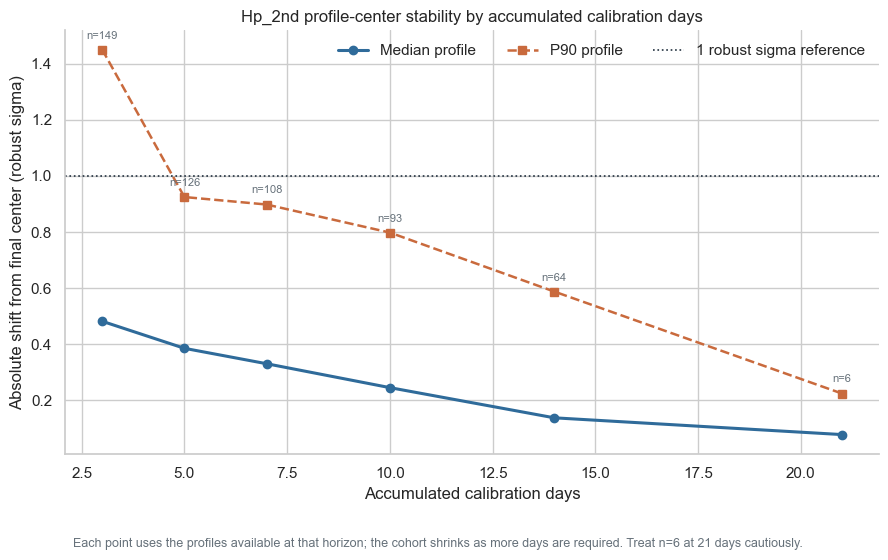

In [8]:
profile_lookup = candidate_profiles.select([*PROFILE_KEYS, "hp2__median", "hp2__scale"]).to_pandas()
daily_hp2 = daily_pdf.merge(profile_lookup, on=PROFILE_KEYS, how="left")
stability_curve_rows = []
for key, group in daily_hp2.groupby(PROFILE_KEYS, sort=True):
    group = group.sort_values("date")
    for prefix_days in [3, 5, 7, 10, 14, 21]:
        if len(group) < prefix_days:
            continue
        prefix_center = float(group.iloc[:prefix_days]["hp2"].median())
        final_center = float(group["hp2__median"].iloc[0])
        scale = max(float(group["hp2__scale"].iloc[0]), SCALE_FLOORS["hp2"])
        stability_curve_rows.append({
            "machine_number": key[0], "module": int(key[1]), "sv": key[2],
            "prefix_days": prefix_days, "hp2_prefix_median": prefix_center,
            "hp2_final_median": final_center, "abs_center_shift_rz": abs(prefix_center-final_center)/scale,
        })

stability_curves = pd.DataFrame(stability_curve_rows)
stability_curves.to_csv(OUTPUT_ROOT / "profile_stability_curves.csv", index=False)
curve_summary = stability_curves.groupby("prefix_days", as_index=False).agg(
    profiles=("abs_center_shift_rz", "size"),
    median_abs_shift_rz=("abs_center_shift_rz", "median"),
    p90_abs_shift_rz=("abs_center_shift_rz", lambda s: s.quantile(.90)),
)
display(curve_summary)

fig, ax = plt.subplots(figsize=(10.5, 5.5))
ax.plot(curve_summary["prefix_days"], curve_summary["median_abs_shift_rz"], marker="o", lw=2.2, color=PALETTE["blue"], label="Median profile")
ax.plot(curve_summary["prefix_days"], curve_summary["p90_abs_shift_rz"], marker="s", lw=1.8, ls="--", color=PALETTE["orange"], label="P90 profile")
ax.axhline(1.0, color=PALETTE["ink"], ls=":", lw=1.2, label="1 robust sigma reference")
for _, row in curve_summary.iterrows():
    ax.annotate(f"n={int(row['profiles'])}", (row["prefix_days"], row["p90_abs_shift_rz"]), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8, color=PALETTE["grey_dark"])
ax.set(title="Hp_2nd profile-center stability by accumulated calibration days", xlabel="Accumulated calibration days", ylabel="Absolute shift from final center (robust sigma)")
ax.legend(frameon=False, ncol=3)
ax.text(.01, -.22, "Each point uses the profiles available at that horizon; the cohort shrinks as more days are required. Treat n=6 at 21 days cautiously.", transform=ax.transAxes, fontsize=9, color=PALETTE["grey_dark"])
sns.despine()
savefig("03_profile_stability_curve.png")
plt.show()

### 9. Event-response readiness แยกจาก steady readiness

In [9]:
events = events.with_columns(pl.col("event_at").cast(pl.Datetime).dt.date().alias("event_date"))
event_counts = events.group_by([*PROFILE_KEYS, "direction"]).agg(
    pl.len().alias("n_events"), pl.col("event_date").n_unique().alias("n_event_days")
)
directions = pl.DataFrame({"direction": ["Closing", "Opening"]})
event_readiness = (
    candidate_profiles.select(PROFILE_KEYS).unique().join(directions, how="cross")
    .join(event_counts, on=[*PROFILE_KEYS, "direction"], how="left")
    .with_columns(pl.col("n_events").fill_null(0), pl.col("n_event_days").fill_null(0))
    .with_columns(
        pl.when((pl.col("n_events") >= MIN_EVENT_SHADOW) & (pl.col("n_event_days") >= MIN_EVENT_DAYS)).then(pl.lit("SHADOW_VALIDATION"))
        .when((pl.col("n_events") >= MIN_EVENT_CANDIDATE) & (pl.col("n_event_days") >= MIN_EVENT_DAYS)).then(pl.lit("CANDIDATE_PROFILE"))
        .otherwise(pl.lit("INSUFFICIENT_COVERAGE")).alias("event_status")
    ).sort([*PROFILE_KEYS, "direction"])
)
event_readiness.write_csv(OUTPUT_ROOT / "event_profile_readiness.csv")
event_status_summary = event_readiness.group_by("event_status").len().sort("len", descending=True).to_pandas()
display(event_status_summary)

,event_status,len
0,INSUFFICIENT_COVERAGE,524


จำนวน minute-windows มากไม่สามารถใช้แทน clean event ได้ Opening และ SV On ที่ไม่มีตัวอย่างต้องตอบ `INSUFFICIENT_COVERAGE`; Notebook จะไม่สร้าง response profile จาก closing/SV Off ไปเติมช่องว่างให้เอง

### 10. Shadow replay ด้วย threshold ที่เรียนจาก calibration เท่านั้น

In [10]:
score_profile_columns = [*PROFILE_KEYS]
for feature in FEATURES:
    score_profile_columns += [f"{feature}__median", f"{feature}__scale"]

def add_deviation_score(frame: pl.DataFrame) -> pl.DataFrame:
    joined = frame.join(candidate_profiles.select(score_profile_columns), on=PROFILE_KEYS, how="inner")
    expressions = [
        ((pl.col(f) - pl.col(f"{f}__median")) / pl.col(f"{f}__scale")).abs().clip(0, 20).alias(f"abs_rz_{f}")
        for f in FEATURES
    ]
    return joined.with_columns(*expressions).with_columns(
        pl.max_horizontal([pl.col(f"abs_rz_{f}") for f in FEATURES]).alias("deviation_score"),
        ((pl.lit(200.0) - pl.col("hp2")).clip(lower_bound=0) / pl.col("hp2__scale")).alias("hp2_low_evidence"),
    )

calibration_scores = add_deviation_score(retained)
thresholds = calibration_scores.group_by(PROFILE_KEYS).agg(
    pl.col("deviation_score").quantile(.995).alias("alert_threshold"),
    pl.col("deviation_score").quantile(.99).alias("watch_threshold"),
)
shadow_scores = add_deviation_score(shadow).join(thresholds, on=PROFILE_KEYS, how="inner").sort([*PROFILE_KEYS, "minute"])
shadow_scores = shadow_scores.with_columns(
    (pl.col("deviation_score") >= pl.col("alert_threshold")).alias("alert"),
    (pl.col("deviation_score") >= pl.col("watch_threshold")).alias("watch"),
).with_columns(
    (
        pl.col("alert")
        & pl.col("alert").shift(1).over(PROFILE_KEYS).fill_null(False)
        & pl.col("alert").shift(2).over(PROFILE_KEYS).fill_null(False)
        & (pl.col("minute").diff().over(PROFILE_KEYS).dt.total_minutes() == 1)
        & ((pl.col("minute") - pl.col("minute").shift(2).over(PROFILE_KEYS)).dt.total_minutes() == 2)
    ).alias("persistent_3")
)

shadow_summary = shadow_scores.group_by(PROFILE_KEYS).agg(
    pl.len().alias("n_shadow_windows"),
    pl.col("date").n_unique().alias("n_shadow_days"),
    (100 * pl.col("watch").mean()).alias("watch_rate_pct"),
    (100 * pl.col("alert").mean()).alias("alert_rate_pct"),
    (100 * pl.col("persistent_3").mean()).alias("persistent_3_rate_pct"),
    (100 * (pl.col("hp2") < 180).mean()).alias("hp2_below_180_pct"),
    pl.col("hp2").median().alias("shadow_hp2_median"),
    pl.col("deviation_score").median().alias("median_deviation_score"),
).join(thresholds, on=PROFILE_KEYS, how="left")
shadow_summary.write_csv(OUTPUT_ROOT / "shadow_replay_results.csv")
display(shadow_summary.sort("alert_rate_pct", descending=True).head(20).to_pandas())

,machine_number,module,sv,n_shadow_windows,n_shadow_days,watch_rate_pct,alert_rate_pct,persistent_3_rate_pct,hp2_below_180_pct,shadow_hp2_median,median_deviation_score,alert_threshold,watch_threshold
0,081,3,On,44,2,100.0,100.0,90.909091,0.000000,199.40,10.000000,4.721428,4.721428
1,024,1,On,45,2,100.0,100.0,84.444444,0.000000,224.90,10.342176,3.484864,3.484864
2,058,8,On,5,1,100.0,100.0,60.000000,0.000000,198.90,20.000000,3.252004,3.252004
3,056,5,On,61,2,100.0,100.0,90.163934,0.000000,211.40,20.000000,6.744897,6.744897
4,024,3,On,48,2,100.0,100.0,83.333333,0.000000,262.20,20.000000,6.520068,6.520068
5,029,5,On,23,1,100.0,100.0,91.304348,0.000000,209.50,20.000000,4.875597,4.875597
6,119,7,Off,1757,2,100.0,100.0,99.772339,0.000000,215.80,9.000000,2.656664,2.613648
7,124,2,Off,723,2,100.0,100.0,99.446750,0.000000,208.60,20.000000,4.683957,4.683957
8,081,1,On,44,2,100.0,100.0,90.909091,0.000000,212.95,20.000000,10.522040,9.712652
9,081,6,On,44,2,100.0,100.0,90.909091,0.000000,203.05,20.000000,7.700425,7.138350


Threshold นี้เป็น operating candidate จาก calibration quantile ไม่ใช่อัตราความเสียหายจริง `Hp_2nd` low-side evidence ถูกเก็บแยกจาก multivariate deviation เพื่อไม่ให้ค่าตั้งแต่ 180 psi ขึ้นไปถูกตีความเป็น undercharge และค่ามากกว่า 230 psi ต้องเข้าสู่ high-side investigation แยกต่างหาก

### 11. รวมหลักฐานเป็น lifecycle status และ reason codes

In [11]:
hp2_uncertainty = bootstrap_ci[
    (bootstrap_ci["feature"] == "hp2")
    & (bootstrap_ci["block_length_days"] == bootstrap_ci.groupby(PROFILE_KEYS)["block_length_days"].transform("max"))
][[*PROFILE_KEYS, "ci_low", "ci_high", "ci_width", "block_length_days"]]

lifecycle = (
    candidate_profiles.to_pandas()
    .merge(stability.select([*PROFILE_KEYS, "max_abs_half_shift_rz"]).to_pandas(), on=PROFILE_KEYS, how="left")
    .merge(shadow_summary.to_pandas(), on=PROFILE_KEYS, how="left")
    .merge(hp2_uncertainty, on=PROFILE_KEYS, how="left")
)

def classify_profile(row):
    reasons = ["SERVICE_EPOCH_UNVERIFIED", "CONTROLLER_CODEBOOK_PENDING", "HUMAN_APPROVAL_REQUIRED"]
    if row["n_days"] < MIN_STEADY_DAYS:
        reasons.append("CALIBRATION_DAYS_LT_7")
    if row["n_windows"] < MIN_STEADY_WINDOWS:
        reasons.append("ELIGIBLE_WINDOWS_LT_200")
    if row["quarantine_pct"] > MAX_QUARANTINE_PCT:
        reasons.append("QUARANTINE_RATE_GT_5PCT")
    if pd.notna(row["max_abs_half_shift_rz"]) and row["max_abs_half_shift_rz"] > MAX_HALF_SHIFT_RZ:
        reasons.append("CALIBRATION_HALF_SHIFT_GT_1P5_RZ")
    if pd.isna(row.get("n_shadow_days")) or row.get("n_shadow_days", 0) < MIN_SHADOW_DAYS:
        reasons.append("SHADOW_DAYS_LT_3")

    if row["n_days"] < MIN_STEADY_DAYS or row["n_windows"] < MIN_STEADY_WINDOWS:
        status = "INSUFFICIENT_DATA"
    elif row["quarantine_pct"] > MAX_QUARANTINE_PCT or (pd.notna(row["max_abs_half_shift_rz"]) and row["max_abs_half_shift_rz"] > MAX_HALF_SHIFT_RZ):
        status = "REVIEW_REQUIRED"
    elif pd.isna(row.get("n_shadow_days")) or row.get("n_shadow_days", 0) < MIN_SHADOW_DAYS:
        status = "CANDIDATE_PROFILE"
    else:
        status = "SHADOW_VALIDATION"
    return pd.Series({"lifecycle_status": status, "reason_codes": ";".join(reasons)})

lifecycle = pd.concat([lifecycle, lifecycle.apply(classify_profile, axis=1)], axis=1)
lifecycle["profile_version"] = PROFILE_VERSION
lifecycle["feature_version"] = FEATURE_VERSION
lifecycle["source_timezone"] = SOURCE_TIMEZONE
lifecycle["service_epoch"] = "epoch-unverified-20260804-20260901"
lifecycle["auto_activation_allowed"] = False
lifecycle["approver"] = ""
lifecycle["rollback_profile"] = ""
lifecycle.to_csv(OUTPUT_ROOT / "profile_lifecycle_status.csv", index=False)

status_order = ["SHADOW_VALIDATION", "CANDIDATE_PROFILE", "REVIEW_REQUIRED", "INSUFFICIENT_DATA"]
status_counts = lifecycle["lifecycle_status"].value_counts().reindex(status_order, fill_value=0)
display(status_counts.rename_axis("status").reset_index(name="profiles"))

if lifecycle["auto_activation_allowed"].any() or lifecycle["lifecycle_status"].isin(["READY_FOR_APPROVAL", "ACTIVE_FROZEN"]).any():
    raise AssertionError("Safety invariant failed: automatic activation path detected")
print("Safety invariant PASS: no profile can auto-activate or enter ACTIVE_FROZEN")

,status,profiles
0,SHADOW_VALIDATION,39
1,CANDIDATE_PROFILE,3
2,REVIEW_REQUIRED,66
3,INSUFFICIENT_DATA,154


Safety invariant PASS: no profile can auto-activate or enter ACTIVE_FROZEN


### 12. ภาพรวม lifecycle — profile ส่วนใหญ่หยุดอยู่ตรงไหน

Saved: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_autobootstrap\figures\01_profile_lifecycle_status.png


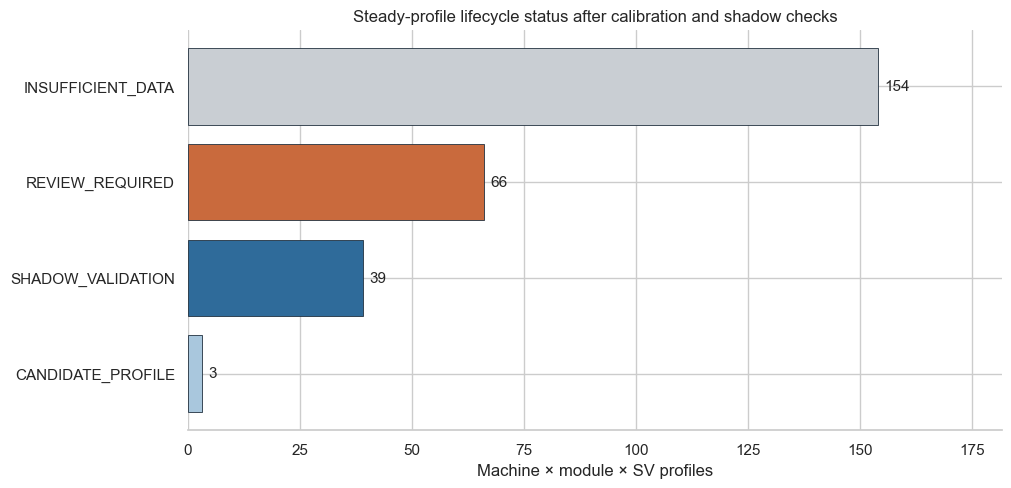

In [12]:
status_colors = {
    "SHADOW_VALIDATION": PALETTE["blue"],
    "CANDIDATE_PROFILE": PALETTE["blue_light"],
    "REVIEW_REQUIRED": PALETTE["orange"],
    "INSUFFICIENT_DATA": PALETTE["grey"],
}
plot_counts = status_counts.sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10.5, 5.2))
bars = ax.barh(plot_counts.index, plot_counts.values, color=[status_colors[x] for x in plot_counts.index], edgecolor=PALETTE["ink"], linewidth=.6)
ax.bar_label(bars, padding=5, fontsize=11)
ax.set(title="Steady-profile lifecycle status after calibration and shadow checks", xlabel="Machine × module × SV profiles", ylabel="")
ax.set_xlim(0, max(plot_counts.values) * 1.18 if max(plot_counts.values) else 1)
sns.despine(left=True)
savefig("01_profile_lifecycle_status.png")
plt.show()

กราฟนี้ไม่ใช่คะแนนสุขภาพเครื่อง แต่เป็นแผนที่ความพร้อมของ profile ยิ่งหยุดที่ `REVIEW_REQUIRED` หรือ `INSUFFICIENT_DATA` มาก ยิ่งบอกว่าต้องเพิ่มหลักฐานหรือทบทวน stability ก่อน ไม่ใช่บังคับให้ระบบออกคำวินิจฉัย

### 13. Readiness map แยก SV Off และ SV On

Saved: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_autobootstrap\figures\02_steady_readiness_heatmap.png


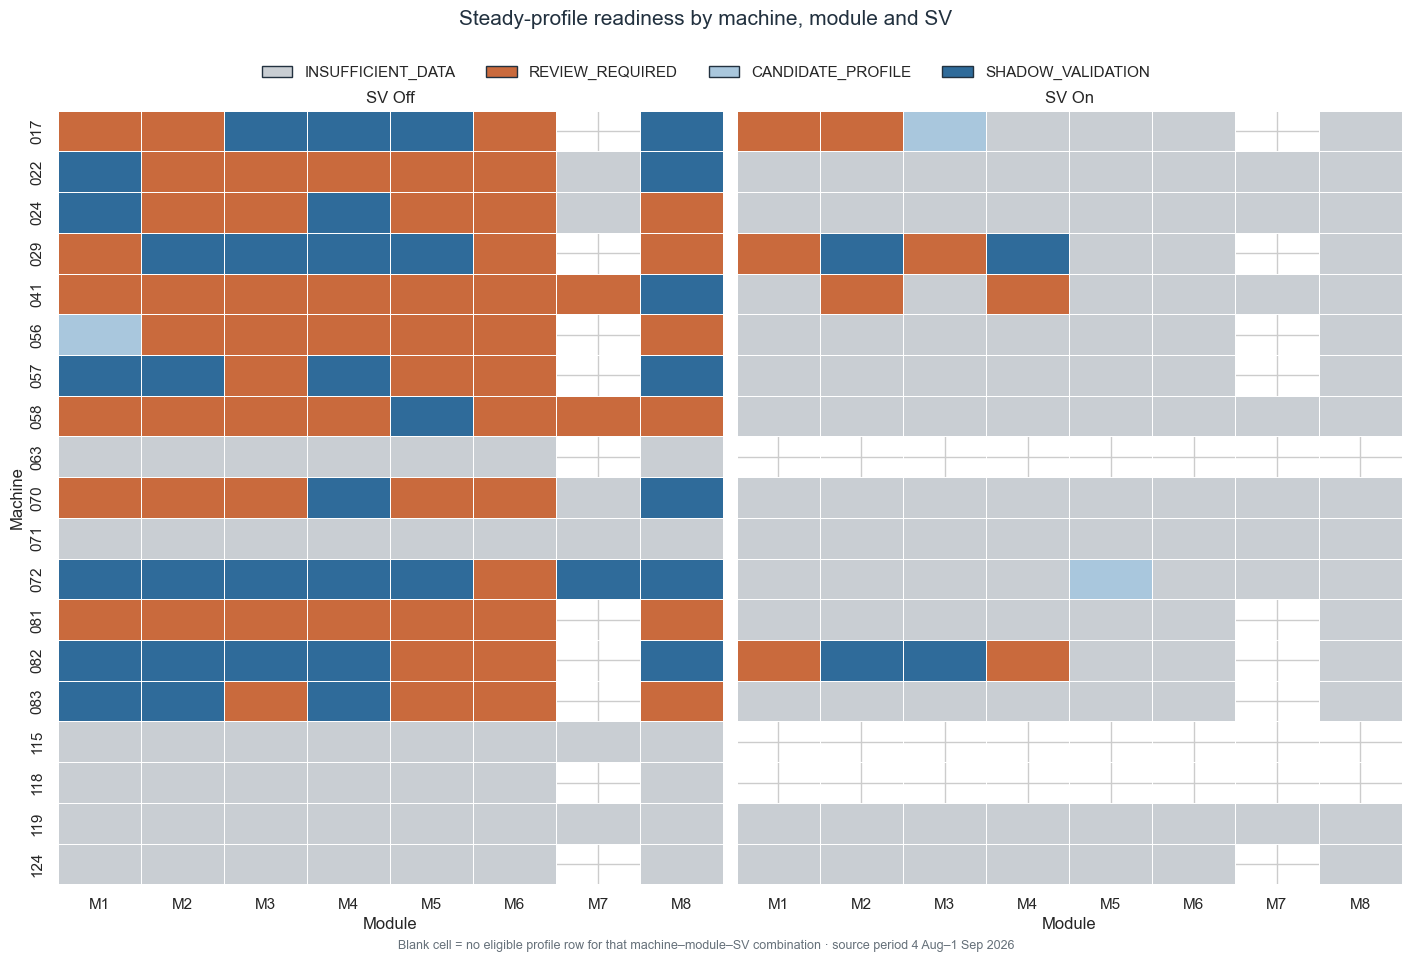

In [13]:
status_value = {"INSUFFICIENT_DATA": 0, "REVIEW_REQUIRED": 1, "CANDIDATE_PROFILE": 2, "SHADOW_VALIDATION": 3}
map_frame = lifecycle.copy()
map_frame["profile_label"] = map_frame["machine_number"].astype(str).str.zfill(3) + " / M" + map_frame["module"].astype(int).astype(str)
map_frame["status_value"] = map_frame["lifecycle_status"].map(status_value)
machines = sorted(map_frame["machine_number"].astype(str).str.zfill(3).unique())

fig, axes = plt.subplots(1, 2, figsize=(14, 8.5), sharey=True, constrained_layout=True)
from matplotlib.colors import ListedColormap
cmap = ListedColormap([status_colors["INSUFFICIENT_DATA"], status_colors["REVIEW_REQUIRED"], status_colors["CANDIDATE_PROFILE"], status_colors["SHADOW_VALIDATION"]])
for ax, sv in zip(axes, ["Off", "On"]):
    part = map_frame[map_frame["sv"] == sv]
    pivot = part.pivot(index="machine_number", columns="module", values="status_value").reindex(index=machines, columns=range(1,9))
    sns.heatmap(pivot, ax=ax, cmap=cmap, vmin=-.5, vmax=3.5, cbar=False, linewidths=.5, linecolor="white", square=False)
    ax.set(title=f"SV {sv}", xlabel="Module", ylabel="Machine" if sv == "Off" else "")
    ax.set_xticklabels([f"M{i}" for i in range(1,9)], rotation=0)
patches = [mpatches.Patch(facecolor=status_colors[s], edgecolor=PALETTE["ink"], label=s) for s in status_order[::-1]]
fig.legend(handles=patches, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(.5, 1.04))
fig.suptitle("Steady-profile readiness by machine, module and SV", y=1.09, fontsize=15, color=PALETTE["ink"])
fig.text(.5, -.015, "Blank cell = no eligible profile row for that machine–module–SV combination · source period 4 Aug–1 Sep 2026", ha="center", fontsize=9, color=PALETTE["grey_dark"])
savefig("02_steady_readiness_heatmap.png")
plt.show()

### 14. `Hp_2nd` uncertainty เทียบจำนวนวัน

Saved: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_autobootstrap\figures\04_hp2_uncertainty_vs_days.png


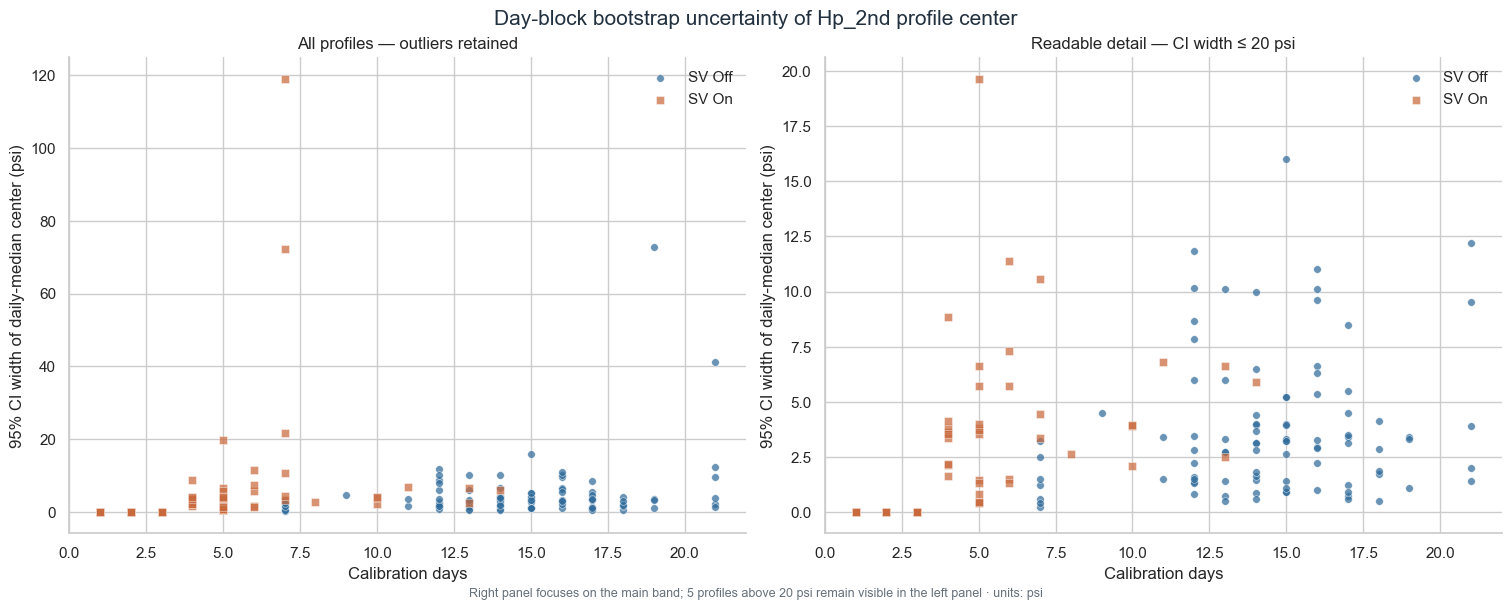

In [14]:
hp2_ci_plot = bootstrap_ci[(bootstrap_ci["feature"] == "hp2")].copy()
hp2_ci_plot = hp2_ci_plot[hp2_ci_plot["block_length_days"] == hp2_ci_plot.groupby(PROFILE_KEYS)["block_length_days"].transform("max")]
focus_limit = 20.0
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), constrained_layout=True)
for ax, focused in zip(axes, [False, True]):
    shown = hp2_ci_plot if not focused else hp2_ci_plot[hp2_ci_plot["ci_width"] <= focus_limit]
    for sv, color, marker in [("Off", PALETTE["blue"], "o"), ("On", PALETTE["orange"], "s")]:
        part = shown[shown["sv"] == sv]
        ax.scatter(part["n_days"], part["ci_width"], s=30, alpha=.72, color=color, marker=marker, label=f"SV {sv}", edgecolors="white", linewidths=.4)
    ax.set(xlabel="Calibration days", ylabel="95% CI width of daily-median center (psi)")
    ax.set_title("All profiles — outliers retained" if not focused else f"Readable detail — CI width ≤ {focus_limit:.0f} psi")
    ax.legend(frameon=False)
    sns.despine(ax=ax)
excluded = int((hp2_ci_plot["ci_width"] > focus_limit).sum())
fig.suptitle("Day-block bootstrap uncertainty of Hp_2nd profile center", fontsize=15, color=PALETTE["ink"])
fig.text(.5, -.02, f"Right panel focuses on the main band; {excluded} profiles above {focus_limit:.0f} psi remain visible in the left panel · units: psi", ha="center", fontsize=9, color=PALETTE["grey_dark"])
savefig("04_hp2_uncertainty_vs_days.png")
plt.show()

จุดที่มีวันมากแต่ CI ยังกว้างไม่ได้แปลว่า sensor เสียโดยอัตโนมัติ อาจสะท้อนหลาย recipe/load หรือ SV/control behavior ที่ยังแบ่ง state ไม่ละเอียดพอ จุดเหล่านี้ควรถูกส่งไป `REVIEW_REQUIRED` หรือเก็บ context เพิ่ม แทนการเพิ่มจำนวนแถวอย่างเดียว

### 15. Event coverage — เห็นทันทีว่าส่วนใดโมเดลยังไม่เคยเรียน

Saved: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_autobootstrap\figures\05_event_coverage.png


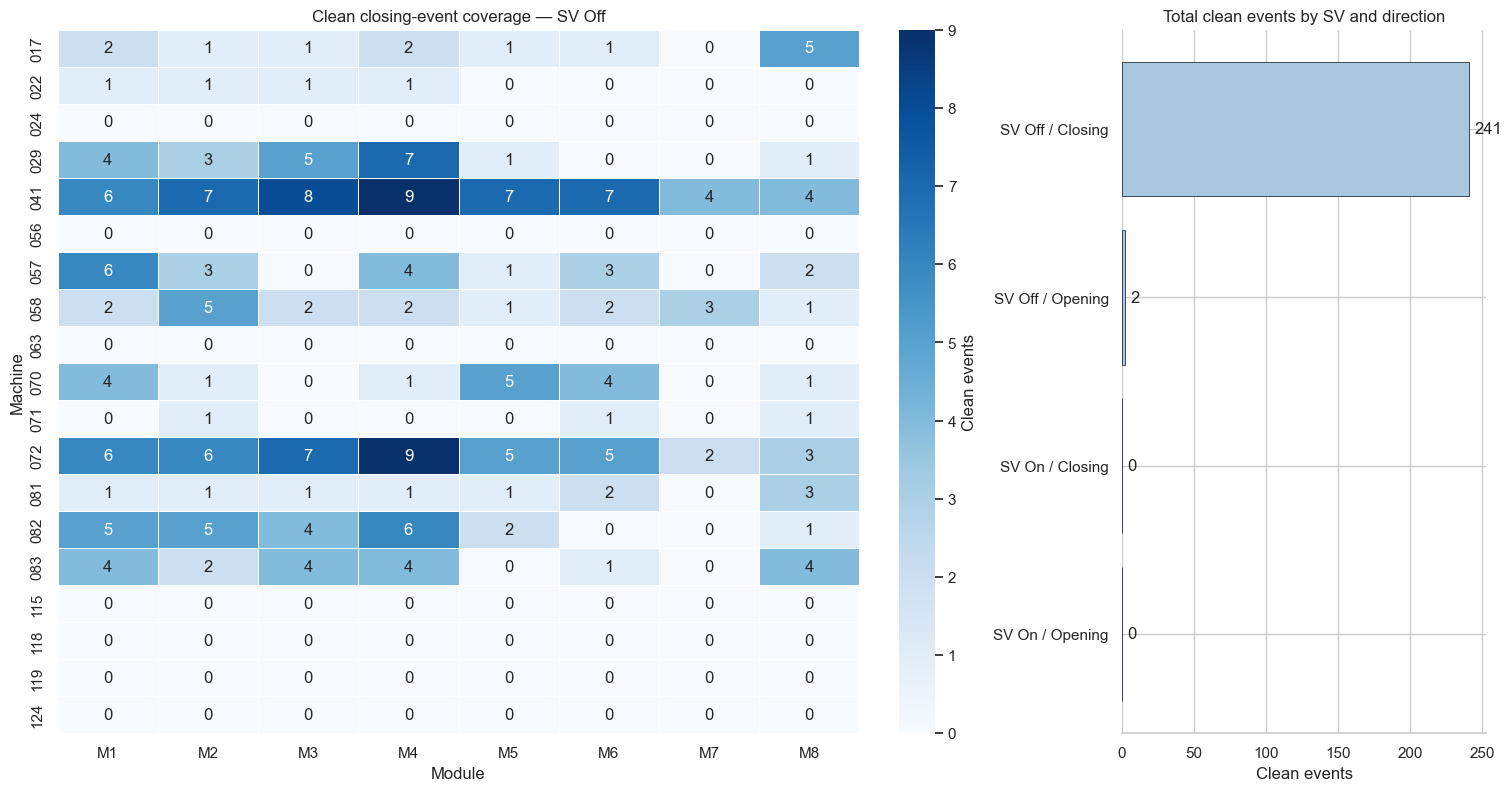

In [15]:
event_pdf = event_readiness.to_pandas()
off_closing = event_pdf[(event_pdf["sv"] == "Off") & (event_pdf["direction"] == "Closing")]
event_pivot = off_closing.pivot(index="machine_number", columns="module", values="n_events").reindex(index=machines, columns=range(1,9)).fillna(0)
coverage_totals = event_pdf.groupby(["sv", "direction"], as_index=False)["n_events"].sum()
coverage_totals["stratum"] = "SV " + coverage_totals["sv"] + " / " + coverage_totals["direction"]

fig, axes = plt.subplots(1, 2, figsize=(15, 7.8), gridspec_kw={"width_ratios": [2.2, 1]}, constrained_layout=True)
sns.heatmap(event_pivot, ax=axes[0], cmap="Blues", linewidths=.4, linecolor="white", annot=True, fmt=".0f", cbar_kws={"label": "Clean events"})
axes[0].set(title="Clean closing-event coverage — SV Off", xlabel="Module", ylabel="Machine")
axes[0].set_xticklabels([f"M{i}" for i in range(1,9)], rotation=0)
ordered = coverage_totals.sort_values("n_events")
bars = axes[1].barh(ordered["stratum"], ordered["n_events"], color=PALETTE["blue_light"], edgecolor=PALETTE["ink"], linewidth=.6)
axes[1].bar_label(bars, padding=4)
axes[1].set(title="Total clean events by SV and direction", xlabel="Clean events", ylabel="")
sns.despine(ax=axes[1], left=True)
savefig("05_event_coverage.png")
plt.show()

### 16. Shadow exceptions — อ่านอัตราควบคู่กับจำนวนตัวอย่าง

Saved: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_autobootstrap\figures\06_shadow_exceptions.png


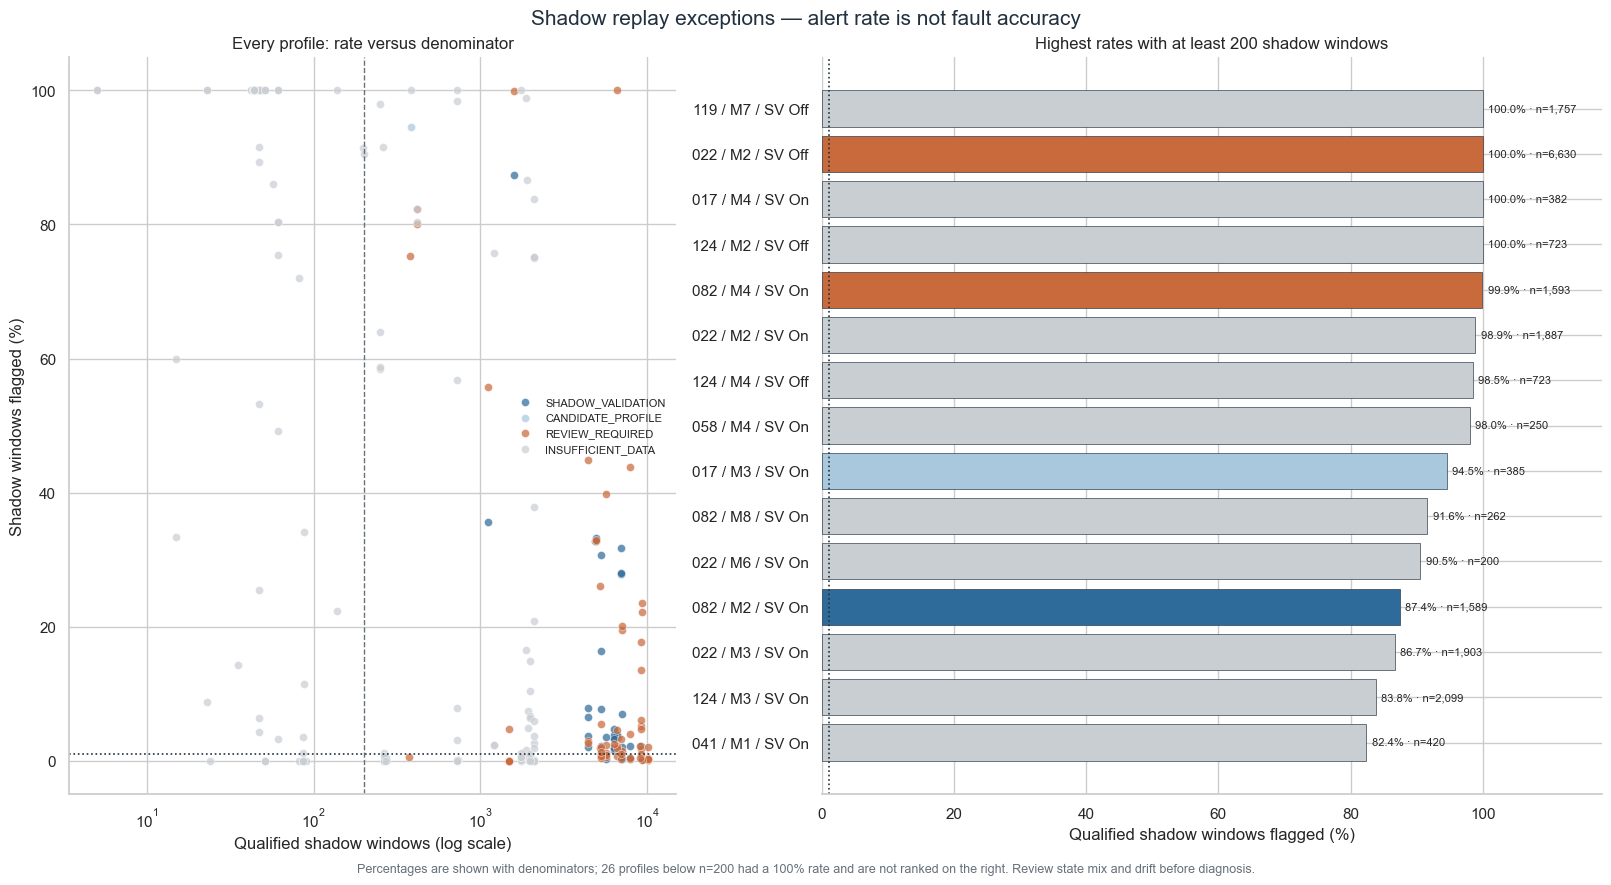

In [16]:
shadow_plot = lifecycle.dropna(subset=["alert_rate_pct"]).copy()
shadow_plot["label"] = shadow_plot["machine_number"].astype(str).str.zfill(3) + " / M" + shadow_plot["module"].astype(int).astype(str) + " / SV " + shadow_plot["sv"]
supported = shadow_plot[shadow_plot["n_shadow_windows"] >= MIN_STEADY_WINDOWS].copy()
ranked = supported.nlargest(15, "alert_rate_pct").sort_values("alert_rate_pct")

fig, axes = plt.subplots(1, 2, figsize=(16, 8.5), gridspec_kw={"width_ratios": [1.05, 1.35]}, constrained_layout=True)
for status in status_order:
    part = shadow_plot[shadow_plot["lifecycle_status"] == status]
    if part.empty:
        continue
    axes[0].scatter(part["n_shadow_windows"], part["alert_rate_pct"], s=34, alpha=.72,
                    color=status_colors[status], label=status, edgecolors="white", linewidths=.4)
axes[0].axhline(1.0, color=PALETTE["ink"], ls=":", lw=1.2)
axes[0].axvline(MIN_STEADY_WINDOWS, color=PALETTE["grey_dark"], ls="--", lw=1.0)
axes[0].set_xscale("log")
axes[0].set(title="Every profile: rate versus denominator", xlabel="Qualified shadow windows (log scale)", ylabel="Shadow windows flagged (%)")
axes[0].legend(frameon=False, fontsize=8)
sns.despine(ax=axes[0])

rank_colors = [status_colors.get(status, PALETTE["grey"]) for status in ranked["lifecycle_status"]]
bars = axes[1].barh(ranked["label"], ranked["alert_rate_pct"], color=rank_colors, edgecolor=PALETTE["ink"], linewidth=.45)
bar_labels = [f"{rate:.1f}% · n={int(n):,}" for rate, n in zip(ranked["alert_rate_pct"], ranked["n_shadow_windows"])]
axes[1].bar_label(bars, labels=bar_labels, padding=4, fontsize=8)
axes[1].axvline(1.0, color=PALETTE["ink"], ls=":", lw=1.2)
axes[1].set(title=f"Highest rates with at least {MIN_STEADY_WINDOWS} shadow windows", xlabel="Qualified shadow windows flagged (%)", ylabel="")
axes[1].set_xlim(0, max(110, ranked["alert_rate_pct"].max() * 1.18 if len(ranked) else 1))
sns.despine(ax=axes[1], left=True)

small_perfect = int(((shadow_plot["n_shadow_windows"] < MIN_STEADY_WINDOWS) & (shadow_plot["alert_rate_pct"] >= 99.99)).sum())
fig.suptitle("Shadow replay exceptions — alert rate is not fault accuracy", fontsize=15, color=PALETTE["ink"])
fig.text(.5, -.02, f"Percentages are shown with denominators; {small_perfect} profiles below n={MIN_STEADY_WINDOWS} had a 100% rate and are not ranked on the right. Review state mix and drift before diagnosis.", ha="center", fontsize=9, color=PALETTE["grey_dark"])
savefig("06_shadow_exceptions.png")
plt.show()

กราฟซ้ายแสดงทุก profile เพื่อให้เห็นว่าเปอร์เซ็นต์สัมพันธ์กับจำนวน shadow windows อย่างไร ส่วนกราฟขวาจัดอันดับเฉพาะ profile ที่มีอย่างน้อย 200 windows ค่า alert สูงใช้ชี้งานที่ต้องตรวจ ไม่ใช่จัดอันดับว่าเครื่องใดเสีย และอาจมาจาก calibration drift, state mix, sensor offset หรือ operating context ที่ยังขาดได้

### 17. Candidate profile package และ audit trail

In [17]:
candidate_columns = [
    *PROFILE_KEYS, "profile_version", "feature_version", "service_epoch", "lifecycle_status", "reason_codes",
    "n_windows", "n_days", "source_start", "source_end", "quarantined_windows", "quarantine_pct",
    "max_abs_half_shift_rz", "n_shadow_windows", "n_shadow_days", "watch_rate_pct", "alert_rate_pct",
    "persistent_3_rate_pct", "ci_low", "ci_high", "ci_width", "auto_activation_allowed", "approver", "rollback_profile",
]
approval_package = lifecycle[[column for column in candidate_columns if column in lifecycle.columns]].copy()
approval_package.to_csv(OUTPUT_ROOT / "approval_package.csv", index=False)

for machine, rows in lifecycle.groupby("machine_number", sort=True):
    payload = {
        "machine_number": str(machine).zfill(3),
        "profile_version": PROFILE_VERSION,
        "feature_version": FEATURE_VERSION,
        "source_timezone": SOURCE_TIMEZONE,
        "service_epoch": "epoch-unverified-20260804-20260901",
        "auto_activation_allowed": False,
        "activation_state": "NOT_AUTHORIZED",
        "required_next_action": "shadow review + service-epoch verification + human approval",
        "profiles": [],
    }
    for _, row in rows.sort_values(["module", "sv"]).iterrows():
        statistics = {}
        for feature in FEATURES:
            statistics[feature] = {
                key: None if pd.isna(row.get(f"{feature}__{key}")) else float(row[f"{feature}__{key}"])
                for key in ["median", "mad", "q05", "q25", "q75", "q95", "scale"]
            }
        payload["profiles"].append({
            "module": int(row["module"]), "sv": row["sv"],
            "lifecycle_status": row["lifecycle_status"], "reason_codes": row["reason_codes"].split(";"),
            "n_windows": int(row["n_windows"]), "n_days": int(row["n_days"]),
            "source_start": str(row["source_start"]), "source_end": str(row["source_end"]),
            "statistics": statistics,
        })
    (PROFILE_ROOT / f"machine_{str(machine).zfill(3)}_candidate.json").write_text(
        json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8"
    )

print(f"Candidate JSON files: {len(list(PROFILE_ROOT.glob('machine_*_candidate.json')))}")
display(approval_package.head(12))

Candidate JSON files: 19


,machine_number,module,sv,profile_version,feature_version,service_epoch,lifecycle_status,reason_codes,n_windows,n_days,...,n_shadow_days,watch_rate_pct,alert_rate_pct,persistent_3_rate_pct,ci_low,ci_high,ci_width,auto_activation_allowed,approver,rollback_profile
0,017,1,Off,autobootstrap-candidate-v2-hp180,minute-state-core-hp180-v2,epoch-unverified-20260804-20260901,REVIEW_REQUIRED,SERVICE_EPOCH_UNVERIFIED;CONTROLLER_CODEBOOK_P...,17086,15,...,6.0,19.510480,19.510480,18.835279,191.50,196.700,5.200,False,,
1,017,1,On,autobootstrap-candidate-v2-hp180,minute-state-core-hp180-v2,epoch-unverified-20260804-20260901,REVIEW_REQUIRED,SERVICE_EPOCH_UNVERIFIED;CONTROLLER_CODEBOOK_P...,209,7,...,2.0,0.536193,0.536193,0.000000,202.40,321.400,119.000,False,,
2,017,2,Off,autobootstrap-candidate-v2-hp180,minute-state-core-hp180-v2,epoch-unverified-20260804-20260901,REVIEW_REQUIRED,SERVICE_EPOCH_UNVERIFIED;CONTROLLER_CODEBOOK_P...,18949,15,...,6.0,21.430575,20.126227,17.812062,203.30,204.700,1.400,False,,
3,017,2,On,autobootstrap-candidate-v2-hp180,minute-state-core-hp180-v2,epoch-unverified-20260804-20260901,REVIEW_REQUIRED,SERVICE_EPOCH_UNVERIFIED;CONTROLLER_CODEBOOK_P...,219,7,...,2.0,75.331565,75.331565,72.148541,214.50,286.800,72.300,False,,
4,017,3,Off,autobootstrap-candidate-v2-hp180,minute-state-core-hp180-v2,epoch-unverified-20260804-20260901,SHADOW_VALIDATION,SERVICE_EPOCH_UNVERIFIED;CONTROLLER_CODEBOOK_P...,20224,15,...,6.0,0.210467,0.210467,0.126280,213.50,216.700,3.200,False,,
5,017,3,On,autobootstrap-candidate-v2-hp180,minute-state-core-hp180-v2,epoch-unverified-20260804-20260901,CANDIDATE_PROFILE,SERVICE_EPOCH_UNVERIFIED;CONTROLLER_CODEBOOK_P...,219,7,...,2.0,94.545455,94.545455,90.909091,225.30,247.000,21.700,False,,
6,017,4,Off,autobootstrap-candidate-v2-hp180,minute-state-core-hp180-v2,epoch-unverified-20260804-20260901,SHADOW_VALIDATION,SERVICE_EPOCH_UNVERIFIED;CONTROLLER_CODEBOOK_P...,19890,15,...,6.0,0.421171,0.421171,0.238663,197.40,200.700,3.300,False,,
7,017,4,On,autobootstrap-candidate-v2-hp180,minute-state-core-hp180-v2,epoch-unverified-20260804-20260901,INSUFFICIENT_DATA,SERVICE_EPOCH_UNVERIFIED;CONTROLLER_CODEBOOK_P...,1664,3,...,3.0,100.000000,100.000000,95.287958,205.80,205.800,0.000,False,,
8,017,5,Off,autobootstrap-candidate-v2-hp180,minute-state-core-hp180-v2,epoch-unverified-20260804-20260901,SHADOW_VALIDATION,SERVICE_EPOCH_UNVERIFIED;CONTROLLER_CODEBOOK_P...,20244,15,...,6.0,2.472605,2.065187,1.447036,195.40,199.400,4.000,False,,
9,017,5,On,autobootstrap-candidate-v2-hp180,minute-state-core-hp180-v2,epoch-unverified-20260804-20260901,INSUFFICIENT_DATA,SERVICE_EPOCH_UNVERIFIED;CONTROLLER_CODEBOOK_P...,168,4,...,2.0,100.000000,100.000000,90.476190,195.65,197.275,1.625,False,,


## Takeaways

### 18. สรุปผลและบันทึก manifest

In [18]:
steady_status_counts = lifecycle["lifecycle_status"].value_counts().to_dict()
event_status_counts = event_pdf["event_status"].value_counts().to_dict()
shadow_valid = lifecycle.dropna(subset=["alert_rate_pct"])
summary = {
    "profile_version": PROFILE_VERSION,
    "feature_version": FEATURE_VERSION,
    "source_period": {"start": str(source_start), "end": str(source_end), "timezone": SOURCE_TIMEZONE},
    "minute_rows": int(minute.height),
    "eligible_rows": int(eligible.height),
    "steady_profiles": int(len(lifecycle)),
    "steady_status_counts": {str(k): int(v) for k, v in steady_status_counts.items()},
    "event_strata": int(len(event_pdf)),
    "event_status_counts": {str(k): int(v) for k, v in event_status_counts.items()},
    "quarantined_windows": int(quarantine_summary["quarantined_windows"].sum()),
    "median_shadow_alert_pct": None if shadow_valid.empty else float(shadow_valid["alert_rate_pct"].median()),
    "worst_shadow_alert_pct": None if shadow_valid.empty else float(shadow_valid["alert_rate_pct"].max()),
    "auto_activation_allowed": False,
    "highest_possible_state_this_run": "SHADOW_VALIDATION",
    "important_limit": "Profile readiness and shadow behavior only; no confirmed fault labels or diagnostic accuracy.",
    "approval_blockers": [
        "service/refill epoch not verified", "controller Busy/Status codebook pending",
        "recipe/load/facility-water context unavailable", "human approval not supplied",
    ],
}
(OUTPUT_ROOT / "analysis_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")

manifest = {
    "notebook": "06_HT9046MX_AutoBootstrap_Profile_Lifecycle_Colab.ipynb",
    "profile_version": PROFILE_VERSION,
    "feature_version": FEATURE_VERSION,
    "inputs": [str(MINUTE_FILE.relative_to(PROJECT_ROOT)), str(BASELINE_FILE.relative_to(PROJECT_ROOT)), str(EVENT_FILE.relative_to(PROJECT_ROOT))],
    "parameters": {
        "calibration_fraction": CALIBRATION_FRACTION, "settle_minutes": SETTLE_MINUTES,
        "min_steady_days": MIN_STEADY_DAYS, "min_steady_windows": MIN_STEADY_WINDOWS, "min_shadow_days": MIN_SHADOW_DAYS,
        "quarantine_z": QUARANTINE_Z, "max_quarantine_pct": MAX_QUARANTINE_PCT,
        "max_half_shift_rz": MAX_HALF_SHIFT_RZ, "bootstrap_replicates": BOOTSTRAP_REPLICATES,
        "event_candidate": MIN_EVENT_CANDIDATE, "event_shadow": MIN_EVENT_SHADOW, "event_days": MIN_EVENT_DAYS,
    },
    "split_contract": "per-profile past calibration then future shadow; no random row split",
    "threshold_contract": "q99/q99.5 from retained calibration only; never from shadow",
    "safety_contract": "no automatic READY_FOR_APPROVAL or ACTIVE_FROZEN transition",
}
(OUTPUT_ROOT / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")

display(Markdown(f'''
### ข้อสรุปที่นำไปใช้ต่อได้

- สร้าง lifecycle status และ reason codes ครบ **{len(lifecycle):,} steady profiles**
- สร้าง event readiness แยกอีก **{len(event_pdf):,} strata** โดยไม่ใช้ steady count ทดแทน event
- Shadow alert rate เป็นเพียง calibration/transfer diagnostic; median = **{summary['median_shadow_alert_pct']:.2f}%**, worst profile = **{summary['worst_shadow_alert_pct']:.2f}%**
- Candidate ทุกไฟล์ระบุ `auto_activation_allowed = false`

### สิ่งที่ผลนี้ยังพิสูจน์ไม่ได้

- ไม่พิสูจน์ว่า profile ที่ผ่าน shadow คือ healthy
- ไม่พิสูจน์ว่า `Hp_2nd < 180 psi` เกิดจาก leak หรือ `Hp_2nd > 230 psi` เกิดจากระบบน้ำ
- ไม่วัด precision/recall เพราะไม่มี technician-confirmed labels
- ไม่อนุญาต Production activation จนกว่า service epoch, codebook, runbook, owner และ approval จะพร้อม
'''))
print(json.dumps(summary, ensure_ascii=False, indent=2))


### ข้อสรุปที่นำไปใช้ต่อได้

- สร้าง lifecycle status และ reason codes ครบ **262 steady profiles**
- สร้าง event readiness แยกอีก **524 strata** โดยไม่ใช้ steady count ทดแทน event
- Shadow alert rate เป็นเพียง calibration/transfer diagnostic; median = **3.90%**, worst profile = **100.00%**
- Candidate ทุกไฟล์ระบุ `auto_activation_allowed = false`

### สิ่งที่ผลนี้ยังพิสูจน์ไม่ได้

- ไม่พิสูจน์ว่า profile ที่ผ่าน shadow คือ healthy
- ไม่พิสูจน์ว่า `Hp_2nd < 180 psi` เกิดจาก leak หรือ `Hp_2nd > 230 psi` เกิดจากระบบน้ำ
- ไม่วัด precision/recall เพราะไม่มี technician-confirmed labels
- ไม่อนุญาต Production activation จนกว่า service epoch, codebook, runbook, owner และ approval จะพร้อม


{
  "profile_version": "autobootstrap-candidate-v2-hp180",
  "feature_version": "minute-state-core-hp180-v2",
  "source_period": {
    "start": "2026-08-04 00:00:00",
    "end": "2026-09-01 17:10:00",
    "timezone": "not encoded"
  },
  "minute_rows": 3548928,
  "eligible_rows": 2667008,
  "steady_profiles": 262,
  "steady_status_counts": {
    "INSUFFICIENT_DATA": 154,
    "REVIEW_REQUIRED": 66,
    "SHADOW_VALIDATION": 39,
    "CANDIDATE_PROFILE": 3
  },
  "event_strata": 524,
  "event_status_counts": {
    "INSUFFICIENT_COVERAGE": 524
  },
  "quarantined_windows": 108521,
  "median_shadow_alert_pct": 3.901825047199497,
  "worst_shadow_alert_pct": 100.0,
  "auto_activation_allowed": false,
  "highest_possible_state_this_run": "SHADOW_VALIDATION",
  "important_limit": "Profile readiness and shadow behavior only; no confirmed fault labels or diagnostic accuracy.",
  "approval_blockers": [
    "service/refill epoch not verified",
    "controller Busy/Status codebook pending",
    "reci

### ไฟล์ผลลัพธ์หลัก

- `profile_lifecycle_status.csv` — สถานะและ reason code ทุก machine–module–SV
- `candidate_profile_statistics.csv` — median/MAD/quantiles/scale หลัง quarantine
- `block_bootstrap_uncertainty.csv` — uncertainty ของ baseline center ระดับวัน
- `profile_stability_curves.csv` — ความนิ่งเมื่อสะสม 3/5/7/10/14/21 วัน
- `event_profile_readiness.csv` — coverage แยก Opening/Closing และ SV
- `shadow_replay_results.csv` — ผล future-only shadow window
- `approval_package.csv` และ `candidate_profiles/*.json` — audit package ที่ยังไม่อนุญาต activation
- `analysis_summary.json` และ `run_manifest.json` — ตัวเลขสรุปและพารามิเตอร์ที่ใช้ rerun

### งานถัดไป

1. ตรวจ profile ที่เป็น `REVIEW_REQUIRED` กับกราฟรายเครื่องและ log หน้างาน
2. นำ service/refill timestamp เข้ามาแยก epoch จริง
3. ยืนยัน `Busy/Status` codebook ก่อนแก้ state contract
4. กำหนด alert budget กับฝ่ายปฏิบัติการ แล้วจึง replay Phase 7